# Inertial Landau-Lifshitz-Gilbert Dynamics

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/04-magnetization/02-iLLG.ipynb)

Here, the [LLG example](#example_LLG) is extended by the inertia of the magnetization, which gives rise to a nutation on top of the precession.
The inertial LLG (iLLG) of {cite:t}`ciornei2011` reads

\begin{align*}
\frac{d\mathbf{n}}{dt} = \gamma \mathbf{n} \times \mathbf{B}
+ \alpha \mathbf{n} \times \left(\frac{d\mathbf{n}}{dt}
+ \tau \frac{d^2\mathbf{n}}{dt^2}\right)
\end{align*}

with the inertial relaxation time $\tau$ (`inertial_time` of the layers).
The nutation has the angular frequency $\omega_n \approx 1/(\alpha\tau)$ and decays on the time scale $\tau$, see {py:class}`iLLG <udkm1Dsim.simulations.magnetization.iLLG>`.
Apart from that, everything is identical to the {py:class}`LLG <udkm1Dsim.simulations.magnetization.LLG>`.

:::{admonition} References {cite}`ciornei2011`
:class: seealso
M.-C. Ciornei, J. M. Rubí, and J.-E. Wegrowe,
*Magnetization dynamics in the inertial regime: Nutation predicted at short time scales*,
[Phys. Rev. B 83, 020410 (2011)](https://doi.org/10.1103/PhysRevB.83.020410)
:::

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Resonant Excitation by THz Pulses

:::{admonition} References {cite}`neeraj2021`
:class: seealso
K. Neeraj, et al.,
*Inertial spin dynamics in ferromagnets*,
[Nat. Phys. 17, 245 (2021)](https://doi.org/10.1038/s41567-020-01040-y)
:::

### Structure

Refer to the [structure example](#example_structure) for more details.

{cite:t}`neeraj2021` investigated a 15 nm thick epitaxial permalloy film on MgO (neglected here), which is magnetized in the film plane by a bias field of 0.35 T. Its Gilbert damping $\alpha = 0.0058$ was measured by ferromagnetic resonance and the inertial relaxation time $\tau = 44$ ps follows from the observed nutation resonance at about 0.6 THz after narrow-band THz excitation.
Here, $\tau = 47.5$ ps is used, so that the simulated nutation resonance is at 0.6 THz, see below.
Besides the `inertial_time`, the iLLG requires the same parameters of the {py:class}`magnetic <udkm1Dsim.structures.parameter_groups.MagneticParameters>` parameter group as the LLG.
As the magnetization is driven by the THz field only, no thermal or elastic parameters and no substrate are required.

In [2]:
M_s = 8.0e5 * u.A / u.m  # saturation magnetization
K_shape = (u.mu_0 * M_s**2 / 2).to("J/m**3")  # shape anisotropy

layer_Py = ud.Layer(
    "Py",
    "Permalloy",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=8700 * u.kg / u.m**3),
    # iLLG parameters
    magnetic=ud.MagneticParameters(
        mag_saturation=M_s,
        gilbert_damping=0.0058,
        inertial_time=47.5 * u.ps,  # nutation resonance at 0.6 THz
        anisotropy=[0, 0, -1] * K_shape,  # hard axis along z
        aniso_exponent=2,
        exch_stiffness=1.3e-11 * u.J / u.m,
        magnetization=(1, 0, 0),
    ),
)
layer_Py.magnetic

Parameter,Symbol,Value,Unit
eff_spin,S,0,
curie_temp,TC,0,K
mf_exch_coupling,J,0,kg m2/s2
lamda,λ,0,
mag_moment,μ,0,A m2
aniso_exponent,β,2,
anisotropy,K,"[0, 0, −4.021×105]",J/m3
exch_stiffness,Aex,"[1.3×10−11, 1.3×10−11, 1.3×10−11]",J/m
mag_saturation,Ms,8×105,J/(m3 T)
magnetization,r,1,


In [3]:
S = ud.Structure("Py film")
S.add_sub_structure(layer_Py, 15)

### Initialize the Simulation

The {py:class}`iLLG <udkm1Dsim.simulations.magnetization.iLLG>` class requires a {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` object and a boolean `force_recalc` in order to overwrite previous simulation results.
Refer to the [LLG example](#example_LLG) for more details.

The iLLG integrates the unit vectors $\mathbf{n}$ and their velocities $\mathbf{v} = \mathrm{d}\mathbf{n}/\mathrm{d}t$.
The relaxation of the velocity on the inertial time makes the iLLG stiff, which the default `LSODA` integrator of the `ode_options` handles.

In [4]:
illg = ud.iLLG(S, True)

illg.save_data = False
illg.disp_messages = True
illg.progress_bar = False

### Ferromagnetic Resonance and Nutation

The external field `B_ext` can also be given per delay as $M \times 3$ array.
In order to obtain the response of the magnetization to all frequencies at once, a short field pulse of 0.1 ps along $y$ in the film plane is added to the static bias field along $x$.
The ratio of the Fourier transforms of the out-of-plane magnetization $m_z$ and of the field pulse is the susceptibility $\chi(f)$, as in Fig. 1(b) of the paper.

:::{versionchanged} 2.6.1
The magnetization maps are returned in cartesian coordinates $[m_x, m_y, m_z]$ by default, as the `magnetization` of the layers.
Before, they were returned in polar coordinates $[r, \phi, \gamma]$, which are still available by `polar=True`.
:::

In [5]:
B_bias = 350 * u.mT
delays = np.r_[0:1000:0.05] * u.ps
B_pulse = 10 * u.mT * np.exp(-4 * np.log(2) * ((delays - 1 * u.ps) / (0.1 * u.ps)) ** 2)

B_ext = np.zeros([len(delays), 3]) * u.mT
B_ext[:, 0] = B_bias
B_ext[:, 1] = B_pulse

init_mag = np.array([1, 0, 0])  # along x
magnetization_map = illg.get_magnetization_map(delays, init_magnetization=init_mag, B_ext=B_ext)
m_z = np.mean(magnetization_map[:, :, 2], axis=1)

# susceptibility from the Fourier transforms
freqs = np.fft.rfftfreq(len(delays), (delays[1] - delays[0]).m_as("s")) * u.Hz
chi = np.abs(np.fft.rfft(m_z) / np.fft.rfft(B_pulse.m_as("T")))

# FMR of the thin film after Kittel and nutation frequency
gamma = abs(layer_Py.gyromagnetic_ratio)
f_FMR = (gamma / (2 * np.pi) * np.sqrt(B_bias * (B_bias + u.mu_0 * M_s))).to("GHz")
alpha = layer_Py.gilbert_damping.magnitude
tau = layer_Py.inertial_time
f_n = (1 / (2 * np.pi * alpha * tau)).to("THz")
# simulated nutation resonance
nutation = (freqs > 0.2 * u.THz) & (freqs < 1 * u.THz)
f_res = freqs[nutation][np.argmax(chi[nutation])].to("THz")
print(f"Kittel FMR frequency: {f_FMR:.1f~P}")
print(f"nutation frequency 1/(2 pi alpha tau) = {f_n:.2f~P}, simulated resonance at {f_res:.2f~P}")

Calculating _magnetization_map_ ...


Elapsed time for _iLLG_: 10.223697 s
Elapsed time for _magnetization_map_: 10.224280 s
Kittel FMR frequency: 19.3 GHz
nutation frequency 1/(2 pi alpha tau) = 0.58 THz, simulated resonance at 0.60 THz


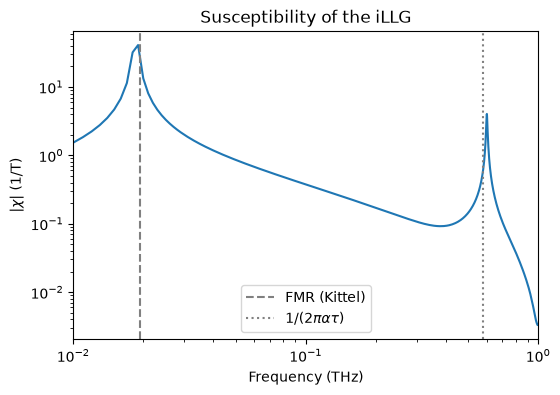

In [6]:
plt.figure(figsize=[6, 4])
plt.loglog(freqs[1:].m_as("THz"), chi[1:])
plt.axvline(f_FMR.m_as("THz"), color="gray", ls="--", label="FMR (Kittel)")
plt.axvline(f_n.m_as("THz"), color="gray", ls=":", label=r"$1/(2\pi\alpha\tau)$")
plt.xlim(1e-2, 1)
plt.xlabel("Frequency (THz)")
plt.ylabel(r"$|\chi|$ (1/T)")
plt.legend()
plt.title("Susceptibility of the iLLG")
plt.show()

Besides the ferromagnetic resonance (FMR) at about 19 GHz, the iLLG shows the nutation resonance at 0.6 THz, two orders of magnitude higher.
The nutation resonance is slightly above $1/(2\pi\alpha\tau)$ due to the effective field.
Above 1 THz, the spectrum of the short field pulse becomes too small for a reliable ratio.

### THz Pulses

Following the experiment, narrowband THz pulses of about 8 cycles along $y$ are added to the static bias field.
As the THz pulses are required for several frequencies, they are generated by a small function `thz_pulse`.
The THz field is orthogonal to the magnetization, so that its torque tilts the magnetization out of the film plane, which component $m_z$ is probed by polar MOKE.
Far from any resonance, $m_z$ simply follows the time integral of the THz field $m_z \approx \gamma \int B_y \mathrm{d}t$, see Eq. (3) of the paper.

As in Fig. 3 of the paper, the response at 0.4 THz is compared to the response at the nutation resonance at 0.6 THz.

Calculating _magnetization_map_ ...


Elapsed time for _iLLG_: 1.887937 s
Elapsed time for _magnetization_map_: 1.888348 s
Calculating _magnetization_map_ ...


Elapsed time for _iLLG_: 1.486880 s
Elapsed time for _magnetization_map_: 1.487231 s


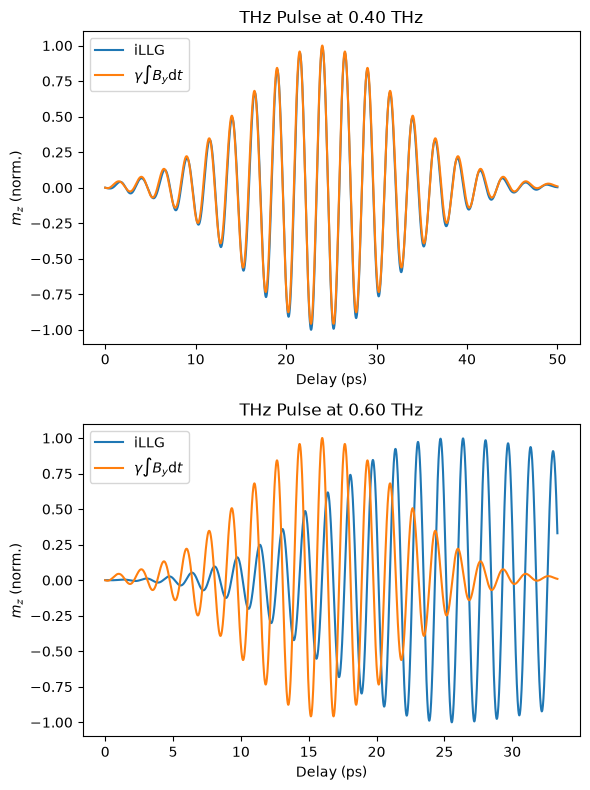

In [7]:
# delays and narrowband THz field with a Gaussian envelope
def thz_pulse(f_THz, B_THz=100 * u.mT, cycles=8):
    duration = cycles / f_THz
    delays = np.r_[0 : 2.5 * duration.m_as("ps") : 0.01] * u.ps
    t_0 = 1.2 * duration
    envelope = np.exp(-4 * np.log(2) * ((delays - t_0) / duration) ** 2)
    return delays, B_THz * envelope * np.sin(2 * np.pi * f_THz * (delays - t_0))


gamma_signed = layer_Py.gyromagnetic_ratio

plt.figure(figsize=[6, 8])
for k, f_THz in enumerate([0.4, 0.6] * u.THz):
    delays, B_y = thz_pulse(f_THz)
    B_ext = np.zeros([len(delays), 3]) * u.mT
    B_ext[:, 0] = B_bias
    B_ext[:, 1] = B_y

    magnetization_map = illg.get_magnetization_map(
        delays, init_magnetization=init_mag, B_ext=B_ext
    )
    m_z = np.mean(magnetization_map[:, :, 2], axis=1)
    # off-resonant response, i.e. the time integral of the THz field
    m_z_int = (gamma_signed * np.cumsum(B_ext[:, 1]) * (delays[1] - delays[0])).m_as("")

    plt.subplot(2, 1, k + 1)
    plt.plot(delays, m_z / np.max(np.abs(m_z)), label="iLLG")
    plt.plot(delays, m_z_int / np.max(np.abs(m_z_int)), label=r"$\gamma \int B_y \mathrm{d}t$")
    plt.xlabel("Delay (ps)")
    plt.ylabel("$m_z$ (norm.)")
    plt.legend(loc="upper left")
    plt.title(f"THz Pulse at {f_THz:.2f~P}")

plt.tight_layout()
plt.show()

At 0.4 THz, the magnetization follows the integrated THz field in phase.
At the nutation resonance, the response is resonantly enhanced and builds up with a phase shift of about 90°, as observed in the paper, and the nutation keeps ringing after the THz pulse.

### Nutation Resonance

Now the THz frequency is scanned as in Fig. 4 of the paper.
The amplitude of $m_z$ is normalized by the off-resonant response $|\gamma| B_\mathrm{THz}/\omega$ of a THz field with the angular frequency $\omega$, which reveals the nutation resonance.

In [8]:
illg.disp_messages = False  # no messages for the scan
frequencies = np.r_[0.3:1.05:0.05] * u.THz
response = np.zeros(len(frequencies))
B_THz = 100 * u.mT
for i, f_THz in enumerate(frequencies):
    delays, B_y = thz_pulse(f_THz, B_THz)
    B_ext = np.zeros([len(delays), 3]) * u.mT
    B_ext[:, 0] = B_bias
    B_ext[:, 1] = B_y

    magnetization_map = illg.get_magnetization_map(
        delays, init_magnetization=init_mag, B_ext=B_ext
    )
    m_z = np.mean(magnetization_map[:, :, 2], axis=1)
    # normalization by the off-resonant response
    response[i] = np.max(np.abs(m_z)) * (2 * np.pi * f_THz / (gamma * B_THz)).m_as("")

print(f"largest response at {frequencies[np.argmax(response)]:.2f~P}")

largest response at 0.60 THz


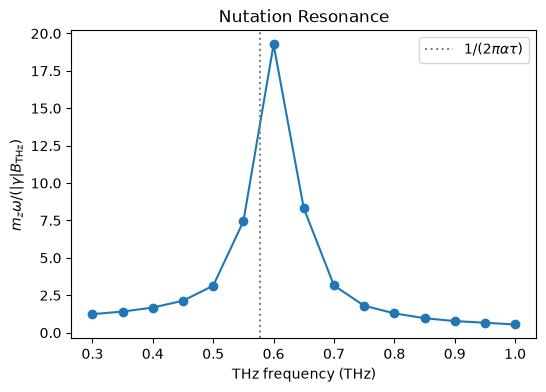

In [9]:
plt.figure(figsize=[6, 4])
plt.plot(frequencies.m_as("THz"), response, "o-")
plt.axvline(f_n.m_as("THz"), color="gray", ls=":", label=r"$1/(2\pi\alpha\tau)$")
plt.xlabel("THz frequency (THz)")
plt.ylabel(r"$m_z \omega / (|\gamma| B_\mathrm{THz})$")
plt.legend()
plt.title("Nutation Resonance")
plt.show()

The response shows a pronounced resonance at the nutation frequency.
The resonance of the experiment is much broader, which {cite:t}`neeraj2021` attribute to the large bandwidth of their THz pulses and to the distribution of inertial times in the film.

## Nutation after Optical Excitation

:::{admonition} References {cite}`de2025`
:class: seealso
A. De, J. Schlegel, A. Lentfert, L. Scheuer, B. Stadtmüller, P. Pirro, G. von Freymann, U. Nowak, and M. Aeschlimann,
*Magnetic nutation: Transient separation of magnetization from its angular momentum*,
[Phys. Rev. B 111, 014432 (2025)](https://doi.org/10.1103/PhysRevB.111.014432)
:::

{cite:t}`de2025` observed a nutation at about 0.1 THz on top of the GHz precession of 5 nm and 2.8 nm thin permalloy films after an excitation with a femtosecond laser pulse.
The ultrafast demagnetization reduces the shape anisotropy within some hundred femtoseconds and suddenly tilts the effective field, which is much faster than the nutation period.
Without inertia, the magnetization would start to precess instantaneously around the new effective field.
With inertia, the magnetization first accelerates towards the effective field, which starts the nutation.

The paper writes the inertial term as $\eta d^2\mathbf{n}/dt^2$ with the nutation time scale $\eta = \alpha\tau$ independent of the damping, and finds $\eta = 1.6$ ps.
A damping of $\alpha = 0.01$ is assumed and $\tau = \eta/\alpha$ is set for a 5 nm thick permalloy film in the external field of $(0, 110, 30)$ mT of their simulations, which has a small out-of-plane component.

In [10]:
eta = 1.6 * u.ps  # nutation time scale
layer_Py.gilbert_damping = 0.01
layer_Py.inertial_time = eta / 0.01

S_5nm = ud.Structure("5 nm Py film")
S_5nm.add_sub_structure(layer_Py, 5)

illg = ud.iLLG(S_5nm, True)
illg.save_data = False
illg.disp_messages = True
illg.progress_bar = False

llg = ud.LLG(S_5nm, True)
llg.save_data = False
llg.disp_messages = False
llg.progress_bar = False

B_ext = np.array([0, 110, 30]) * u.mT

Instead of simulating the heating of the film, the demagnetization is given directly as `mag_amplitude_map`, see the [LLG example](#example_LLG): the magnetization is quenched by 20% within 100 fs and recovers in a fast and a slow step on time scales of 1 ps and 200 ps.
The magnetization starts in the equilibrium of the external field and the anisotropy before the excitation (`equilibrate=True`).

In [11]:
delays = np.r_[-5:300:0.05] * u.ps
t = delays.to("ps").magnitude
t_pos = np.clip(t, 0, None)
quench = 0.2 * (1 - np.exp(-t_pos / 0.1)) * (0.5 * np.exp(-t_pos / 1) + 0.5 * np.exp(-t_pos / 200))
mag_amplitude_map = np.tile((1 - quench)[:, np.newaxis], (1, S_5nm.get_number_of_layers()))

magnetization_map_illg = illg.get_magnetization_map(
    delays, mag_amplitude_map=mag_amplitude_map, B_ext=B_ext, equilibrate=True
)
magnetization_map_llg = llg.get_magnetization_map(
    delays, mag_amplitude_map=mag_amplitude_map, B_ext=B_ext, equilibrate=True
)
# directions of the magnetization averaged over the film
n_illg = np.mean(magnetization_map_illg, axis=1)
n_illg /= np.linalg.norm(n_illg, axis=1)[:, np.newaxis]
n_llg = np.mean(magnetization_map_llg, axis=1)
n_llg /= np.linalg.norm(n_llg, axis=1)[:, np.newaxis]

Calculating _magnetization_map_ ...
No explicit initial magnetization given - use magnetization of layers instead.


Elapsed time for _iLLG_: 1.436335 s
Elapsed time for _magnetization_map_: 1.436470 s


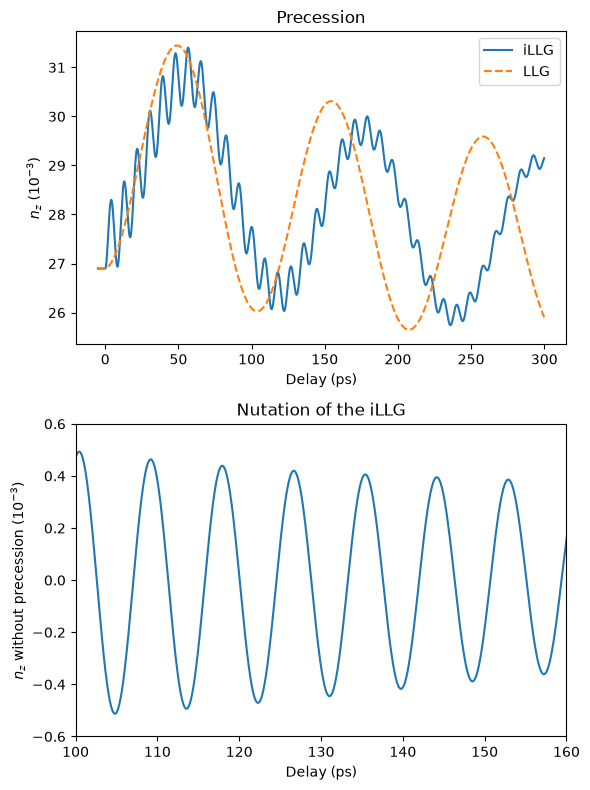

In [12]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.plot(delays, n_illg[:, 2] * 1e3, label="iLLG")
plt.plot(delays, n_llg[:, 2] * 1e3, "--", label="LLG")
plt.xlabel("Delay (ps)")
plt.ylabel("$n_z$ ($10^{-3}$)")
plt.legend()
plt.title("Precession")

# subtract the precession by a moving average over one nutation period
dt = (t[1] - t[0]) * 1e-12
f_n = (1 / (2 * np.pi * eta)).m_as("Hz")
window = int(round(1 / f_n / dt))
background = np.convolve(n_illg[:, 2], np.ones(window) / window, mode="same")
nutation = n_illg[:, 2] - background

plt.subplot(2, 1, 2)
plt.plot(delays, nutation * 1e3)
plt.xlim(100, 160)
plt.ylim(-0.6, 0.6)
plt.xlabel("Delay (ps)")
plt.ylabel(r"$n_z$ without precession ($10^{-3}$)")
plt.title("Nutation of the iLLG")

plt.tight_layout()
plt.show()

Both models precess at about 10 GHz, but the inertia slows down the precession of the iLLG and adds the nutation on top of it.
Subtracting the precession, which corresponds to the subtraction of the FMR background in the paper, reveals the nutation.
Its frequency follows from the Fourier transform and agrees with the nutation frequency {cite:p}`de2025`

\begin{align*}
\omega_n = \frac{\sqrt{1 + 4|\gamma|\eta B} + 1}{2\eta} \approx \frac{1}{\eta},
\end{align*}

which is slightly shifted above $1/\eta$ by the effective field $B$.

### Trajectory of the Magnetization

Fig. 4(d) of the paper sketches the trajectory of the magnetization viewed along the effective field, which spirals into the new equilibrium after the sudden tilt.
In order to see such a spiral within a few precession periods, the damping is increased to $\alpha = 0.1$ here, keeping $\eta = \alpha\tau$ and hence the nutation frequency constant.
Moreover, the demagnetization of 10% does not recover, so that the effective field stays constant after the excitation.

In [13]:
layer_Py.gilbert_damping = 0.1
layer_Py.inertial_time = eta / 0.1

delays = np.r_[-5:800:0.05] * u.ps
t = delays.to("ps").magnitude
quench = 0.1 * (1 - np.exp(-np.clip(t, 0, None) / 0.1))
mag_amplitude_map = np.tile((1 - quench)[:, np.newaxis], (1, S_5nm.get_number_of_layers()))

illg.disp_messages = False
magnetization_map = illg.get_magnetization_map(
    delays, mag_amplitude_map=mag_amplitude_map, B_ext=B_ext, equilibrate=True
)
n = np.mean(magnetization_map, axis=1)
n /= np.linalg.norm(n, axis=1)[:, np.newaxis]

The effective field points almost along $y$ in the film plane, so that the plane perpendicular to it is spanned by the in-plane component $n_x$ and the out-of-plane component $n_z$.
Due to the shape anisotropy, the precession is elliptical, which is why both components are normalized to their largest deviation from the new equilibrium, i.e. from the center of the spiral.

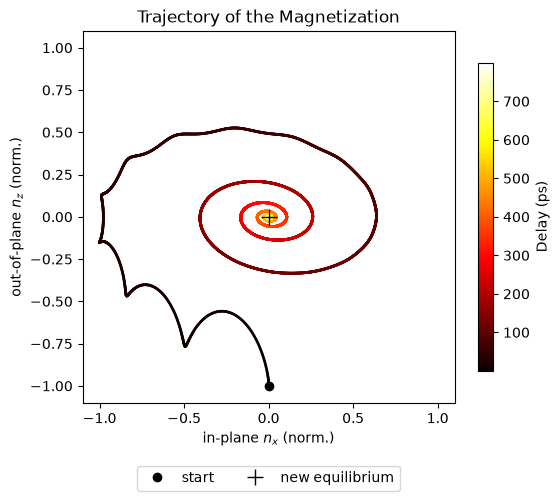

In [14]:
after = t >= 0
# deviation from the new equilibrium at the end, normalized per component
deviation = n[after][:, [0, 2]] - n[-1, [0, 2]]
deviation /= np.max(np.abs(deviation), axis=0)

plt.figure(figsize=[6, 5])
plt.scatter(deviation[:, 0], deviation[:, 1], c=t[after], s=1, cmap="hot")
plt.colorbar(label="Delay (ps)", shrink=0.8)
plt.plot(deviation[0, 0], deviation[0, 1], "ko", label="start")
plt.plot(0, 0, "k+", ms=12, label="new equilibrium")
plt.gca().set_aspect("equal")
plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)
plt.xlabel(r"in-plane $n_x$ (norm.)")
plt.ylabel(r"out-of-plane $n_z$ (norm.)")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.title("Trajectory of the Magnetization")
plt.show()

The magnetization cannot follow the sudden tilt of the effective field instantaneously: it starts with nutation loops, which decay on the inertial time $\tau = \eta/\alpha = 16$ ps, and spirals into the new equilibrium by the damped precession.